# AQ-10 Autism Screening Data: What Machine Learning Can and Can't Learn

**Data:** UCI *Autism Screening Adult* dataset (Thabtah, 2017; CC BY 4.0). 704 AQ-10-Adult screening records (respondents aged 17–64) collected through the ASDTests mobile app: each has the **AQ-10** (a 10-item Autism Spectrum Quotient screening questionnaire) plus demographic and background questions. Most were self-completed; some were completed by a parent, relative, health care professional or other person, and some don't record who completed them (counts in Section 1).

**Questions**
1. Is the dataset's ASD label something a model can meaningfully *predict*?
2. Can a **shorter questionnaire** reproduce the AQ-10 screening decision while keeping sensitivity high?
3. Do background factors (age, sex, neonatal jaundice, family history of autism, ethnicity) predict a positive screen?

> **Important:** the label is a **screening result, not a diagnosis.** No one in this dataset had a clinical ASD assessment recorded. Nothing here is a diagnostic tool.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from aq10 import ITEMS, load_aq10, rank_items, sha256, short_form_cv

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:.3f}".format)
RAW = ROOT / "data" / "raw" / "autism_screening_adult_uci426.zip"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2, "lines.linewidth": 2,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

## 1. Data

In [2]:
assert sha256(RAW) == "c57b29866c9715ff49ff4cce52228e6c460bdce3f615000c33b4d53df99d6d09"
df = load_aq10(RAW)
y = df["screen_positive"].values
relation = df["relation"].str.strip("' ")
print(f"{len(df)} records; screen-positive {y.sum()} ({y.mean():.1%}); "
      f"age missing or implausible: {df['age'].isna().sum()}; ethnicity not reported: {(df['ethnicity'] == 'Not reported').sum()}")
print(f"completed by: self {(relation == 'Self').sum()}, someone else {relation.notna().sum() - (relation == 'Self').sum()}, "
      f"not recorded {relation.isna().sum()}; ages {df['age'].min():.0f}-{df['age'].max():.0f} (aged 17: {(df['age'] == 17).sum()})")
df[["age", "male", "jaundice", "family_autism", "used_app_before"]].describe().loc[["mean", "50%", "min", "max"]]

704 records; screen-positive 189 (26.8%); age missing or implausible: 3; ethnicity not reported: 95
completed by: self 522, someone else 87, not recorded 95; ages 17-64 (aged 17: 18)


,age,male,jaundice,family_autism,used_app_before
mean,29.194,0.521,0.098,0.129,0.017
50%,27.000,1.000,0.000,0.000,0.000
min,17.000,0.000,0.000,0.000,0.000
max,64.000,1.000,1.000,1.000,1.000


## 2. The label is the scoring rule

The AQ-10 score is the number of items answered in the autism-associated direction. Cross-tabulating that score against the dataset's `Class/ASD` label:

In [3]:
print("result column equals the sum of A1-A10 for every row:", bool((df["result"] == df[ITEMS].sum(axis=1)).all()))
pd.crosstab(df["result"].rename("AQ-10 score"), df["Class/ASD"])

result column equals the sum of A1-A10 for every row: True


Class/ASD,NO,YES
AQ-10 score,,
0,14,0
1,33,0
2,74,0
3,110,0
4,131,0
5,83,0
6,70,0
7,0,57
8,0,55


In [4]:
tree = DecisionTreeClassifier(max_depth=2, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
acc = cross_val_score(tree, df[["result"]], y, cv=cv, scoring="accuracy")
print(f"Depth-2 decision tree on the total score, 5-fold CV accuracy: {acc.mean():.3f}")
print(export_text(tree.fit(df[["result"]], y), feature_names=["AQ-10 score"]))

Depth-2 decision tree on the total score, 5-fold CV accuracy: 1.000
|--- AQ-10 score <= 6.50
|   |--- class: 0
|--- AQ-10 score >  6.50
|   |--- class: 1



**Every row with a score of 7 or more is labelled ASD, and every row below 7 is not.** A model trained on the ten items, or on `result`, is just relearning a fixed sum-and-threshold rule, so near-perfect accuracy on this dataset (common in published notebooks) demonstrates nothing about autism. The original version of this project used a synthetic Kaggle derivative of this data (fractional ages, noisy labels), and its accuracy figures had the same problem.

The useful questions are the ones the rule *doesn't* answer by construction: whether fewer items would do (Section 3), and whether anything outside the questionnaire relates to a positive screen (Section 4).

## 3. How short can the screen be?

The reference standard here is the **full AQ-10 decision** (score ≥ 7), not a diagnosis. For each length *k* = 1…10, inside every training fold:

1. rank items by how much more often screen-positive respondents endorse them,
2. keep the top *k* and sum them,
3. choose the highest cutoff that still reaches **≥ 95% sensitivity** on the training fold, because a screen should miss few people.

The items and cutoff are then applied unchanged to the held-out fold. Stratified 5-fold CV, repeated 10 times (50 folds per *k*).

In [5]:
folds = pd.concat([short_form_cv(df, k, n_repeats=10, target_sensitivity=0.95) for k in range(1, 11)])
summary = folds.groupby("k")[["sensitivity", "specificity", "PPV", "NPV"]].agg(["mean", "std"])
summary.columns = [f"{m} {s}" for m, s in summary.columns]
summary["most common items"] = folds.groupby("k")["items"].agg(lambda s: s.value_counts().index[0])
summary["usual cutoff"] = folds.groupby("k")["cutoff"].agg(lambda s: s.value_counts().index[0])
summary[["sensitivity mean", "sensitivity std", "specificity mean", "specificity std", "PPV mean", "NPV mean", "usual cutoff", "most common items"]]

,sensitivity mean,sensitivity std,specificity mean,specificity std,PPV mean,NPV mean,usual cutoff,most common items
k,,,,,,,,
1,1.000,0.000,0.000,0.000,0.268,NaN,0,A9_Score
2,0.996,0.009,0.342,0.284,0.383,0.996,1,"A5_Score,A9_Score"
3,1.000,0.000,0.548,0.042,0.449,1.000,1,"A5_Score,A6_Score,A9_Score"
4,0.994,0.011,0.749,0.031,0.594,0.997,2,"A4_Score,A5_Score,A6_Score,A9_Score"
5,0.974,0.022,0.854,0.025,0.712,0.989,3,"A3_Score,A4_Score,A5_Score,A6_Score,A9_Score"
6,0.956,0.034,0.889,0.057,0.769,0.983,4,"A3_Score,A4_Score,A5_Score,A6_Score,A9_Score,A..."
7,1.000,0.000,0.848,0.026,0.709,1.000,4,"A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A..."
8,1.000,0.000,0.932,0.019,0.846,1.000,5,"A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A..."
9,1.000,0.000,0.963,0.015,0.911,1.000,6,"A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A..."


Item ranking on the full data (most to least discriminating): ['A9_Score', 'A5_Score', 'A6_Score', 'A4_Score', 'A3_Score', 'A10_Score', 'A7_Score', 'A2_Score', 'A1_Score', 'A8_Score']


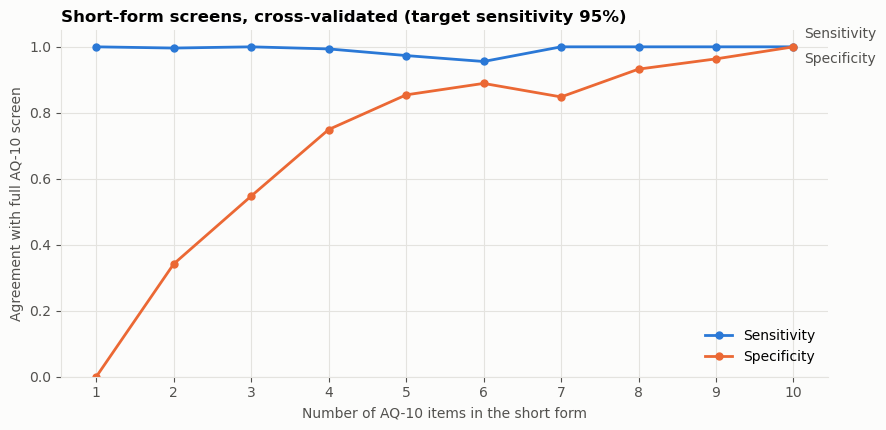

In [6]:
print("Item ranking on the full data (most to least discriminating):", rank_items(df[ITEMS], y))
s = summary
fig, ax = plt.subplots(figsize=(9, 4.4))
ks = s.index.values
ax.plot(ks, s["sensitivity mean"], color=BLUE, marker="o", markersize=5, label="Sensitivity")
ax.plot(ks, s["specificity mean"], color=ORANGE, marker="o", markersize=5, label="Specificity")
ax.annotate("Sensitivity", (10, s["sensitivity mean"].iloc[-1]), xytext=(8, 6), textcoords="offset points", color=INK2)
ax.annotate("Specificity", (10, s["specificity mean"].iloc[-1]), xytext=(8, -12), textcoords="offset points", color=INK2)
ax.set_xticks(ks)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Number of AQ-10 items in the short form")
ax.set_ylabel("Agreement with full AQ-10 screen")
ax.set_title("Short-form screens, cross-validated (target sensitivity 95%)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIGS / "short_form_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Do background factors predict a positive screen?

Logistic regression on age, sex, neonatal jaundice, family history of autism, prior use of the app, and ethnicity (one-hot, with "Not reported" as its own category), using **no questionnaire items**. Imputation, scaling and encoding are fit inside each fold. Stratified 5-fold CV repeated 10 times. The reported range is the 2.5th–97.5th percentile across the 10 repeats; it reflects cross-validation variability, not a confidence interval for the population AUC.

In [7]:
numeric = ["age", "male", "jaundice", "family_autism", "used_app_before"]
pre = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("eth", OneHotEncoder(handle_unknown="ignore", min_frequency=10), ["ethnicity"]),
])
model = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=2000, class_weight="balanced"))])
X = df[numeric + ["ethnicity"]]
aucs, aps = [], []
for r in range(10):
    p = cross_val_predict(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=r), method="predict_proba")[:, 1]
    aucs.append(roc_auc_score(y, p))
    aps.append(average_precision_score(y, p))
print(f"ROC-AUC {np.mean(aucs):.3f} (repeat range {np.percentile(aucs, 2.5):.3f}-{np.percentile(aucs, 97.5):.3f}); "
      f"PR-AUC {np.mean(aps):.3f} vs positive rate {y.mean():.3f}")

coef = pd.Series(model.fit(X, y).named_steps["lr"].coef_[0],
                 index=model.named_steps["pre"].get_feature_names_out()).sort_values()
coef.rename("standardized log-odds coefficient").to_frame()

ROC-AUC 0.728 (repeat range 0.716-0.736); PR-AUC 0.455 vs positive rate 0.268


,standardized log-odds coefficient
eth__ethnicity_Middle Eastern,-0.980
eth__ethnicity_Not reported,-0.884
eth__ethnicity_South Asian,-0.833
eth__ethnicity_Pasifika,-0.706
eth__ethnicity_Asian,-0.521
eth__ethnicity_infrequent_sklearn,-0.192
num__male,-0.122
num__age,-0.001
num__used_app_before,0.097
num__jaundice,0.124


In [8]:
def repeated_auc(cols, categorical):
    steps = [("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
              [c for c in cols if c not in categorical])]
    if categorical:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), categorical))
    m = Pipeline([("pre", ColumnTransformer(steps)), ("lr", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    return np.mean([roc_auc_score(y, cross_val_predict(m, df[cols], y, method="predict_proba",
                    cv=StratifiedKFold(5, shuffle=True, random_state=r))[:, 1]) for r in range(10)])

pd.Series({
    "All background factors (incl. ethnicity)": repeated_auc(numeric + ["ethnicity"], ["ethnicity"]),
    "Without ethnicity": repeated_auc(numeric, []),
    "Ethnicity only": repeated_auc(["ethnicity"], ["ethnicity"]),
}, name="mean ROC-AUC").to_frame()

,mean ROC-AUC
All background factors (incl. ethnicity),0.728
Without ethnicity,0.618
Ethnicity only,0.705


In [9]:
rates = pd.DataFrame({
    "screen-positive rate": [df.loc[df[c] == v, "screen_positive"].mean() for c in ["family_autism", "jaundice"] for v in (1, 0)],
    "n": [(df[c] == v).sum() for c in ["family_autism", "jaundice"] for v in (1, 0)],
}, index=["family history: yes", "family history: no", "neonatal jaundice: yes", "neonatal jaundice: no"])
rates

,screen-positive rate,n
family history: yes,0.473,91
family history: no,0.238,613
neonatal jaundice: yes,0.406,69
neonatal jaundice: no,0.254,635


## 5. Findings

1. **The ASD label in this dataset is exactly "AQ-10 score ≥ 7"** (704 of 704 rows; a depth-2 tree reaches 100% CV accuracy on the total score). Classifiers trained on the questionnaire items can only relearn this rule, so their accuracy says nothing about detecting autism. This invalidates the premise of the original project.
2. **A 5-item short form** (most often items 3, 4, 5, 6 and 9) with a cutoff of 3 kept **97.4% sensitivity and 85.4% specificity** against the full AQ-10 decision across 50 held-out folds (NPV 0.989, PPV 0.712). With 8 items, sensitivity was 100% and specificity 93.2%. The trade-off isn't perfectly monotone (7 items: specificity 0.848) because cutoffs are whole numbers chosen to protect sensitivity.
3. **Background factors relate weakly to a positive screen, and most of that signal is ethnicity.** Without the questionnaire, ROC-AUC was 0.728, but 0.618 without ethnicity and 0.705 with ethnicity alone. Family history of autism (47.3% vs 23.8% screen-positive) and neonatal jaundice (40.6% vs 25.4%) were associated with higher screen-positive rates.

**Interpretation:** the ethnicity effect most plausibly reflects who used the app and cultural differences in answering self-report items, not biology. It's a caution that AQ-10 cutoffs may behave differently across groups, not a predictor anyone should use.

## 6. Limitations

* **No diagnoses.** Every result concerns agreement with the AQ-10 screen, and the AQ-10's own accuracy against clinical diagnosis can't be estimated from this data.
* **Self-selected app users**, so the 26.8% screen-positive rate is far above population prevalence and PPV/NPV don't transfer to clinical settings.
* **Short-form results are internal:** items and cutoffs were chosen within training folds, but there's no external sample. Any short form would need validation against diagnostic assessment.
* **Small subgroups:** several ethnicity groups have fewer than 20 people; 95 people didn't report ethnicity. The same 95 records also lack who completed the test, so "Not reported" marks a data-collection gap rather than an ethnic group; treat its coefficient with caution.
* **Not all records are self-reports by adults:** 87 were completed by someone else, and 18 respondents were aged 17, although the dataset is labelled "18 and more".